# Etapa — Análise de sentimentos

**Objetivo desta etapa:** construir uma primeira linha de base (*baseline*) para classificar o sentimento de comentários sobre produtos em português, em três classes: **positivo, negativo e neutro**.

**Dados:** [RePro](https://github.com/lucasnil/repro) (PROPOR 2024), com 10.000 avaliações da Americanas.com rotuladas por anotadores humanos. Licença CC BY-NC-SA 4.0 (uso não comercial).

**Modelo:** TF-IDF (palavras e pares de palavras) + Regressão Logística.

**Roteiro do notebook:**
1. Carregar os dados
2. Preparar os textos e os rótulos
3. Treinar o classificador
4. Avaliar (métricas e matriz de confusão)
5. Testar exemplos novos (positivos, negativos, neutros e no estilo YouTube)
6. Registrar os erros de classificação
7. Analisar os resultados

## 1. Carregar os dados

In [2]:
import ast, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score, f1_score

pd.set_option("display.max_colwidth", 200)
SEED = 42

# O arquivo é baixado por `python utils/baixar_dados.py` (rodar a partir de src-pln/)
CAMINHO = Path("../data/RePro.csv")
df = pd.read_csv(CAMINHO)
print(df.shape)
df[["product_name", "product_brand", "review_title", "review_text", "overall_rating", "polarity"]].head()

ModuleNotFoundError: No module named 'numpy'

## 2. Preparar os textos e os rótulos

No RePro, a coluna `polarity` é uma lista, porque uma avaliação pode ter mais de um sentimento:

- `['POSITIVO']`, `['NEGATIVO']`, `['NEUTRO']` → um sentimento só
- `['NEGATIVO', 'POSITIVO']` → **misto** (elogia uma coisa e critica outra)

**Decisão:** nesta etapa vamos trabalhar com 3 classes (positivo, negativo, neutro). Os casos **mistos ficam fora do treino** e são analisados à parte no final.

In [2]:
df["polarity_list"] = df["polarity"].apply(ast.literal_eval)

def rotulo(pol):
    if len(pol) > 1:
        return "misto"
    return pol[0].lower()

df["sentimento"] = df["polarity_list"].apply(rotulo)
df["sentimento"].value_counts()

sentimento
positivo    4127
negativo    3449
misto       2018
neutro       409
Name: count, dtype: int64

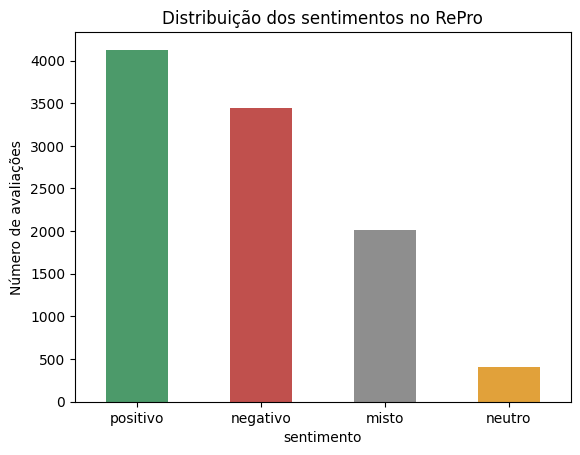

In [3]:
ax = df["sentimento"].value_counts().plot(kind="bar", color=["#4C9A6A", "#C0504D", "#8E8E8E", "#E1A13A"])
ax.set_title("Distribuição dos sentimentos no RePro")
ax.set_ylabel("Número de avaliações")
plt.xticks(rotation=0); plt.show()

**Observação:** a classe **neutro é muito rara** (cerca de 4% dos dados). Para o modelo não ignorar essa classe, vamos usar `class_weight="balanced"`, que dá mais peso aos erros nas classes pequenas.

**Pré-processamento:** juntamos título e texto da avaliação, passamos para minúsculas, removemos links e números. Os acentos são removidos pelo próprio `TfidfVectorizer` (`strip_accents="unicode"`).
Não removemos *stopwords*: palavras como "não" e "nem" estão nas listas comuns de stopwords, mas mudam completamente o sentimento ("bom" × "não é bom").

In [4]:
def limpar(texto):
    texto = str(texto).lower()
    texto = re.sub(r"http\S+|www\.\S+", " ", texto)   # links
    texto = re.sub(r"\d+", " ", texto)                   # números
    texto = re.sub(r"\s+", " ", texto).strip()
    return texto

df["texto"] = (df["review_title"].fillna("") + ". " + df["review_text"].fillna("")).apply(limpar)

dados = df[df["sentimento"] != "misto"].copy()
mistos = df[df["sentimento"] == "misto"].copy()
print("Para treino/teste:", len(dados), "| mistos (análise à parte):", len(mistos))
dados[["texto", "sentimento"]].sample(5, random_state=SEED)

Para treino/teste: 7985 | mistos (análise à parte): 2018


,texto,sentimento
6386,"produto de excelente qualidade. tanto a mochila como a capa para o notebook vieram em perfeito estado e bem embalados. o material é muito resistente, não é aquelas mochilas com tecido molinho. tem...",positivo
1585,"bom produto. produto de boa qualidade, de facil manuseio, chegou dentro do prazo gostei bastante dele.",positivo
5139,não gostei. quando faz duas xícaras transborda. e joga o pó para à xícara,negativo
2450,"entrega de produto errado !comprei um kit permanente afro mairibel e recebi um kit alisamento no lugar. estou extremamente insatisfeita com a compra deste produto e com esta empresa, pois comprei ...",negativo
7778,"tudo certo, e antes do prazo gostei..... serviço com rapidez e eficiência. eu recomendo comprar nesse site..",positivo


## 3. Treinar o classificador

Divisão **80% treino / 20% teste**, estratificada (mantém a proporção de cada classe nos dois conjuntos).

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    dados["texto"], dados["sentimento"], test_size=0.2, stratify=dados["sentimento"], random_state=SEED)

modelo = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.9, strip_accents="unicode", sublinear_tf=True)),
    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", C=2.0, random_state=SEED)),
])
modelo.fit(X_train, y_train)
print("Treino:", len(X_train), "| Teste:", len(X_test))
print("Tamanho do vocabulário:", len(modelo.named_steps["tfidf"].vocabulary_))

Treino: 6388 | Teste: 1597
Tamanho do vocabulário: 17769


## 4. Avaliação

In [6]:
y_pred = modelo.predict(X_test)
print(f"Acurácia: {accuracy_score(y_test, y_pred):.3f}")
print(f"F1 macro: {f1_score(y_test, y_pred, average='macro'):.3f}\n")
print(classification_report(y_test, y_pred, digits=3))

Acurácia: 0.951


F1 macro: 0.883

              precision    recall  f1-score   support

    negativo      0.938     0.959     0.948       690
      neutro      0.685     0.768     0.724        82
    positivo      0.992     0.961     0.977       825

    accuracy                          0.951      1597
   macro avg      0.872     0.896     0.883      1597
weighted avg      0.953     0.951     0.951      1597



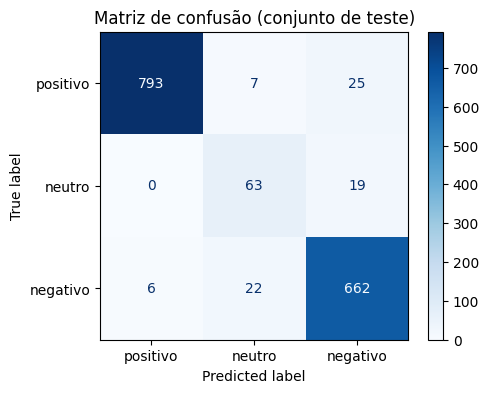

In [7]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=["positivo", "neutro", "negativo"], cmap="Blues", ax=ax)
ax.set_title("Matriz de confusão (conjunto de teste)")
plt.show()

**Linha de base trivial:** para saber se o modelo aprendeu algo, comparamos com um "modelo" que sempre chuta a classe mais comum.

In [8]:
from sklearn.dummy import DummyClassifier
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
yd = dummy.predict(X_test)
print(f"Sempre a classe mais comum → acurácia {accuracy_score(y_test, yd):.3f} | F1 macro {f1_score(y_test, yd, average='macro'):.3f}")

Sempre a classe mais comum → acurácia 0.517 | F1 macro 0.227


### O que o modelo aprendeu?

As palavras e expressões com maior peso para cada classe:

In [9]:
tfidf = modelo.named_steps["tfidf"]; clf = modelo.named_steps["clf"]
termos = np.array(tfidf.get_feature_names_out())
tabela = {}
for i, classe in enumerate(clf.classes_):
    tabela[classe] = termos[np.argsort(clf.coef_[i])[::-1][:15]]
pd.DataFrame(tabela)

,negativo,neutro,positivo
0,nao,duvida,bom
1,nao gostei,duvidas,excelente
2,veio,gostaria,otimo
3,ruim,saber,recomendo
4,com,produto nao,gostei
5,nao recomendo,gostaria de,muito
6,que,alguem,bem
7,pessimo,qual,boa
8,nem,ainda,super
9,ja,pergunta,otima


## 5. Testar exemplos novos

Frases escritas por nós, incluindo comentários no **estilo do YouTube** (gírias, emojis, ironia), que é o domínio onde o projeto será aplicado.

In [10]:
exemplos = pd.DataFrame([
    ("Produto excelente, chegou rápido e funciona perfeitamente", "positivo"),
    ("Meu filho amou o brinquedo, super recomendo!", "positivo"),
    ("Péssimo, quebrou no segundo dia de uso", "negativo"),
    ("Não recomendo, a qualidade é horrível e o suporte não responde", "negativo"),
    ("Recebi o produto hoje", "neutro"),
    ("Alguém sabe se esse modelo tem a versão azul?", "neutro"),
    ("Mano esse carrinho é top demais 🔥🔥", "positivo"),
    ("kkkkk comprei e veio faltando peça, tô passado", "negativo"),
    ("Nossa, que qualidade incrível... durou uma semana 🙄", "negativo"),
    ("Primeira vez que vejo esse canal, qual é o nome da música?", "neutro"),
], columns=["frase", "esperado"])

limpas = exemplos["frase"].apply(limpar)
exemplos["previsto"] = modelo.predict(limpas)
exemplos["confiança"] = modelo.predict_proba(limpas).max(axis=1).round(2)
exemplos["acertou?"] = np.where(exemplos["esperado"] == exemplos["previsto"], "✅", "❌")
exemplos

,frase,esperado,previsto,confiança,acertou?
0,"Produto excelente, chegou rápido e funciona perfeitamente",positivo,positivo,0.96,✅
1,"Meu filho amou o brinquedo, super recomendo!",positivo,positivo,0.96,✅
2,"Péssimo, quebrou no segundo dia de uso",negativo,negativo,0.85,✅
3,"Não recomendo, a qualidade é horrível e o suporte não responde",negativo,negativo,0.91,✅
4,Recebi o produto hoje,neutro,neutro,0.48,✅
5,Alguém sabe se esse modelo tem a versão azul?,neutro,neutro,0.98,✅
6,Mano esse carrinho é top demais 🔥🔥,positivo,neutro,0.68,❌
7,"kkkkk comprei e veio faltando peça, tô passado",negativo,negativo,0.80,✅
8,"Nossa, que qualidade incrível... durou uma semana 🙄",negativo,positivo,0.51,❌
9,"Primeira vez que vejo esse canal, qual é o nome da música?",neutro,neutro,0.66,✅


## 6. Erros de classificação

Todos os erros do conjunto de teste, e uma amostra para leitura:

In [11]:
erros = pd.DataFrame({"texto": X_test, "real": y_test, "previsto": y_pred})
erros = erros[erros["real"] != erros["previsto"]]
print(f"Total de erros: {len(erros)} de {len(y_test)} ({len(erros)/len(y_test):.1%})\n")
print(erros.groupby(["real", "previsto"]).size().sort_values(ascending=False).to_string())

Total de erros: 79 de 1597 (4.9%)

real      previsto
positivo  negativo    25
negativo  neutro      22
neutro    negativo    19
positivo  neutro       7
negativo  positivo     6


In [12]:
erros.sample(12, random_state=SEED)

,texto,real,previsto
1910,como fazer para verificar a arritmia?. bom dia! comprei dois aparelhos desses. um para uso pessoal e outro para um amigo! somente não consegui identificar como medir a arritmia. onde indica a anor...,neutro,negativo
9738,"ótimo desmpenho.. já é o meu segundo zenfone, não tem igual entre os intermediários.",positivo,negativo
4002,"mais barato. quando o telefone chegou, aqui na minha cidade ja estava quase . mais barato",neutro,negativo
5671,"otimo. estamos bem satisfeitos com esse purificador. nao achei barulhento. sao níveis de agua... o único detalhe é que a a agua natural sai com menos pressão, a agua fria e gelada tem melhor press...",positivo,negativo
2256,"do adolescente ao idoso.. desde que a pessoa saiba ler, pode aprender (e se divertir) com esse livro, não sendo necessário ser estudante das ciências da saúde. no caso de profissionais/estudantes ...",positivo,negativo
7460,"se não vai entregar, pq vende?. recebem mas não entregam ""a sua avaliação pode ser publicada em nossos sites e ajudará outras pessoas na escolha de seus produtos.""",negativo,neutro
3771,informação incorreta. no anúncio consta com cooler. mas na verdade só vem com os buracos para o cooler né ?,neutro,negativo
4880,não tem como avaliar. como posso avaliar um produto que não foi entregue?,neutro,negativo
1741,cervejinha sem congelar.. o aparelho no meu caso funcionou como imaginava. instalei em meu freezer flex e quando eu quero que o produto fique na temperatura desejada regulo o mesmo espero soar o a...,positivo,negativo
5943,"perda de peso. com uma semana já da pra notar a eficácia do produto! regula bem o intestino, aliás, até demais kkk pra quem quer perder peso esse é o produto",positivo,negativo


### Avaliações mistas (fora do treino)

Como o modelo classifica avaliações que elogiam e criticam ao mesmo tempo?

In [13]:
mistos["previsto"] = modelo.predict(mistos["texto"])
print(mistos["previsto"].value_counts(normalize=True).round(3).to_string())
mistos[["texto", "previsto"]].sample(5, random_state=SEED)

previsto
negativo    0.539
positivo    0.455
neutro      0.006


,texto,previsto
7372,"ruim!!. por um tempo, meses funcionou razoavelmente “bem”. após, dor de cabeça total. desconfigurava total. desligava sozinha. a data se desconfigurava sozinha. depois parou de ligar. usei cerca d...",negativo
1575,"bom produto. presente para minha mae, gostei funciona, mais tem pouca potecia , porem funciona. so cuidado com cabelo molhado, usa apenas úmido.",positivo
1300,"bom. produto bom , porém a estampa deixa a desejar , diferente do que mostra na foto .",positivo
8469,"e um exelente relogio só que venho com a pulseira dura de mais tambem minha nota fiscal que não se encontra. ola boa tarde meu relógio venho com um defeito, a pulseira esta muito dura ela não fica...",negativo
1380,"bom custo benefício. comprei a capa para usar de back up enquanto lavo a outra que tenho . parece um tnt grosso meio plastificado , faz um pouco de barulho ( no estilo sacolinha de mercado) depois...",positivo


## 7. Análise dos resultados

### Resultados principais

| Métrica (teste, 1.597 avaliações) | TF-IDF + Regressão Logística | Sempre a classe mais comum |
|---|---|---|
| Acurácia | **0,951** | 0,517 |
| F1 macro | **0,883** | 0,227 |

| Classe | Precisão | Revocação | F1 |
|---|---|---|---|
| Positivo | 0,992 | 0,961 | 0,977 |
| Negativo | 0,938 | 0,959 | 0,948 |
| Neutro | 0,685 | 0,768 | 0,724 |

**1. A linha de base é forte para positivo e negativo.** Com F1 acima de 0,94 nas duas classes, um modelo simples já separa bem elogio de reclamação. As palavras mais importantes fazem sentido: "excelente", "recomendo", "adorei" para positivo; "não gostei", "péssimo", "defeito", "frágil" para negativo. O *bigrama* "não recomendo" aparece como sinal negativo, o que confirma a decisão de **não remover stopwords** como "não".

**2. O neutro é o ponto fraco (F1 0,72).** Há dois motivos:
- É uma classe rara: 409 de 7.985 avaliações (5%), só 82 no teste.
- No RePro, "neutro" significa quase sempre **pergunta ou produto ainda não recebido/usado** ("dúvida", "gostaria de saber", "ainda não recebi"). O modelo aprendeu esse padrão, e não "ausência de opinião".

**3. Os erros mais comuns são de fronteira, não aleatórios** (79 erros no total, 4,9%):
- **Negativo → neutro (22):** reclamações sobre entrega escritas como pergunta ("já fazem duas semanas... ainda vai chegar no prazo??"). O tom de pergunta engana o modelo.
- **Neutro → negativo (19):** o inverso: "eu não recebi o produto", "nem chegou" foram rotulados como neutros pelos anotadores, mas têm palavras negativas.
- **Positivo → negativo (25):** elogios com negação ou ressalva: "**não** tem igual entre os intermediários", "secadora seca bem **porém**...". O TF-IDF vê "não" e "porém" e não entende que o sentido é positivo.

**4. Avaliações mistas:** o modelo divide os mistos entre negativo (54%) e positivo (45%), quase nunca neutro. Isso é esperado, já que ele só conhece três classes, mas mostra que **uma avaliação mista vira positiva ou negativa dependendo de qual parte pesa mais**. Para o monitoramento de marca, isso pode esconder críticas importantes.

**5. Teste com frases no estilo YouTube (8 de 10 acertos).** Os erros foram justamente os casos típicos de redes sociais:
- **Gíria:** "Mano esse carrinho é top demais 🔥🔥" → previsto **neutro**. "Top" e emojis quase não aparecem nas avaliações da loja.
- **Ironia:** "Nossa, que qualidade incrível... durou uma semana 🙄" → previsto **positivo**. O modelo só vê "qualidade incrível".

São só 10 frases, então não servem como métrica. Mas já indicam o problema central do projeto: **o modelo treinado em avaliações de loja deve perder desempenho em comentários do YouTube.** Isso será medido com a amostra rotulada manualmente pelo grupo.

### Limitações e próximos passos

- O TF-IDF não entende contexto, ordem das palavras nem ironia → testar rede neural (Etapa 4) e Transformer, como o BERTimbau (Etapa 5), que o artigo do RePro reporta com F1 de 0,91 em sentimento.
- A classe neutro tem poucos exemplos → avaliar aumento de dados ou pseudo-rotulagem com a B2W.
- Os mistos foram excluídos → discutir se vale uma 4ª classe no produto final.
- Gírias, emojis e ironia → principal fonte de erro esperada no YouTube.